# LAB 11 - K Means Clustering Techniques

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df=pd.read_excel('CustomerData.xlsx')

In [8]:
df.head()

,Customer,Age,Sales
0,Catalyst Healthcare,30,1203494.0
1,Synergy Solutions,4,3136995.0
2,AstroSphere Enterprises,20,76323.0
3,Maruti MechCore,16,276539.0
4,Ambuja Auto Industries,33,272796.0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 580 entries, 0 to 579
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Customer  580 non-null    object 
 1   Age       580 non-null    int64  
 2   Sales     580 non-null    float64
dtypes: float64(1), int64(1), object(1)
memory usage: 13.7+ KB


In [10]:
# removing first column as it is not required in clusteing
df.drop(columns=['Customer'], inplace=True)
df.head()

,Age,Sales
0,30,1203494.0
1,4,3136995.0
2,20,76323.0
3,16,276539.0
4,33,272796.0


In [11]:
# scaling both columns
from sklearn.preprocessing import StandardScaler

In [12]:
sc = StandardScaler()
df_new = sc.fit_transform(df)
df_new

array([[ 1.34466309, -0.05559463],
       [-1.66431738,  0.39843707],
       [ 0.18736291, -0.32028099],
       ...,
       [ 1.46039311, -0.3025133 ],
       [ 1.34466309, -0.29803733],
       [-0.96993727, -0.2780374 ]], shape=(580, 2))

In [13]:
# Applying K means clustering algorithm
from sklearn.cluster import KMeans

In [14]:
# let's try with initial 4 clusters
kmeans = KMeans(n_clusters = 4, random_state = 44)

In [15]:
import warnings
warnings.filterwarnings('ignore')
kmeans_fit = kmeans.fit(df_new)

In [16]:
# finding lables of clusters
kmeans.labels_

array([0, 1, 3, 3, 0, 0, 3, 3, 3, 1, 0, 3, 0, 3, 3, 3, 1, 3, 3, 3, 0, 3,
       0, 2, 3, 0, 1, 3, 3, 2, 1, 0, 3, 1, 0, 1, 3, 0, 1, 1, 1, 3, 0, 3,
       0, 1, 3, 1, 1, 0, 1, 3, 1, 1, 1, 3, 0, 1, 0, 1, 2, 1, 3, 0, 2, 3,
       1, 3, 2, 3, 1, 0, 1, 0, 3, 0, 3, 3, 2, 3, 0, 0, 1, 0, 1, 3, 3, 3,
       1, 3, 3, 3, 0, 3, 1, 3, 1, 0, 0, 3, 3, 3, 1, 0, 3, 3, 1, 3, 1, 3,
       2, 1, 3, 1, 1, 1, 1, 1, 2, 3, 1, 1, 3, 3, 3, 3, 1, 2, 1, 3, 3, 3,
       1, 2, 0, 2, 3, 1, 3, 2, 3, 1, 2, 0, 3, 0, 1, 3, 0, 3, 1, 0, 3, 0,
       3, 1, 1, 3, 3, 0, 3, 2, 1, 0, 3, 3, 0, 2, 3, 1, 0, 1, 3, 3, 0, 3,
       0, 3, 1, 1, 1, 1, 0, 2, 3, 2, 3, 1, 0, 3, 0, 0, 0, 1, 0, 1, 3, 3,
       3, 0, 3, 3, 1, 3, 0, 3, 2, 3, 1, 3, 3, 0, 3, 3, 3, 1, 0, 3, 0, 0,
       1, 1, 3, 3, 1, 3, 1, 3, 1, 3, 0, 3, 3, 0, 1, 0, 3, 0, 1, 0, 2, 1,
       1, 1, 0, 0, 1, 3, 3, 0, 1, 3, 1, 3, 3, 0, 1, 0, 3, 3, 1, 0, 0, 0,
       1, 0, 0, 1, 0, 3, 1, 3, 0, 0, 1, 3, 3, 0, 0, 0, 0, 3, 0, 3, 3, 1,
       3, 1, 3, 3, 0, 3, 3, 3, 0, 3, 1, 3, 3, 0, 3,

In [17]:
# estimating within cluster sum of squares (WCSS)
kmeans_fit.inertia_

131.4575537003617

In [18]:
from sklearn.metrics import silhouette_score, silhouette_samples

In [19]:
silhouette_score(df_new, kmeans.labels_) # checking score

0.5775378347614717

In [20]:
wcss = []
silhouette = []
k = 15 # trying with k = 2 to 15
 
for i in range(2, k+1):
    kmeans = KMeans(n_clusters = i, random_state = 44)
    kmeans.fit(df_new)
    wcss.append(kmeans.inertia_)
    score = silhouette_score(df_new, kmeans.labels_)
    silhouette.append(score)

In [22]:
# print the result in the dictionary form
optimal_k = pd.DataFrame({'k' : range(2, k+1),'WCSS' : wcss,'Silhouette Score' : silhouette})
 
optimal_k

,k,WCSS,Silhouette Score
0,2,615.905725,0.719014
1,3,220.471565,0.585073
2,4,131.457554,0.577538
3,5,107.104245,0.533436
4,6,95.078071,0.510177
5,7,71.248267,0.497674
6,8,63.685980,0.481711
7,9,52.950993,0.483434
8,10,45.817921,0.497365
9,11,42.714993,0.489499


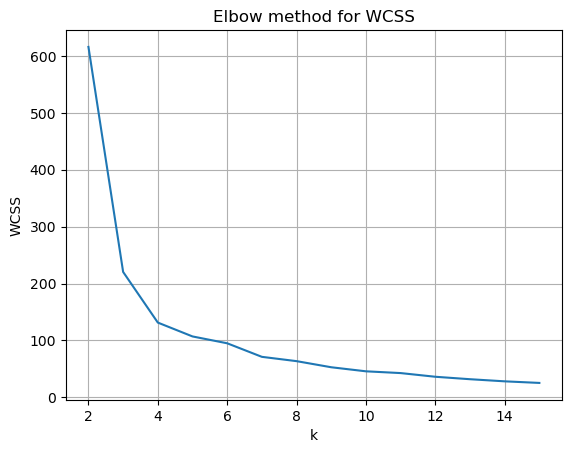

In [23]:
# plot of k values verses silhouette score
sns.lineplot(x = 'k', y ='WCSS', data = optimal_k,
legend='full')
plt.title("Elbow method for WCSS")
plt.grid(True)

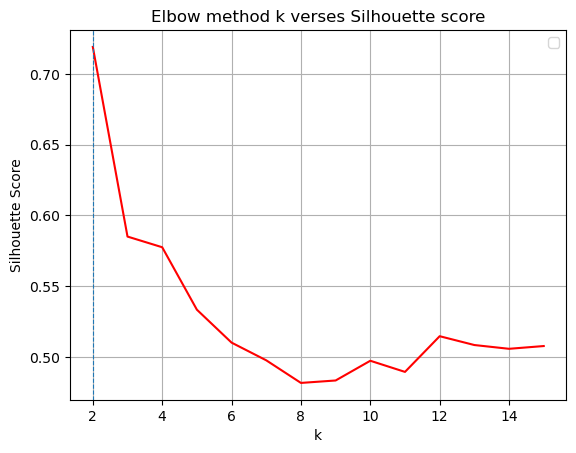

In [27]:
sns.lineplot(x = 'k', y = 'Silhouette Score', data = optimal_k,legend = 'full', color = 'red')
plt.title("Elbow method k verses Silhouette score")
plt.axvline(x= 2, linewidth=0.8, linestyle='--')
plt.legend()
plt.grid(True)

In [28]:
# Redesign the clusters with k = 2
kmeans = KMeans(n_clusters = 2, random_state = 44)
kmeans_fit = kmeans.fit(df_new)

In [29]:
kmeans.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [31]:
# adding additonal column of cluster to original frame
df['Clusters'] = kmeans.labels_
df

,Age,Sales,Clusters
0,30,1203494.0,0
1,4,3136995.0,0
2,20,76323.0,0
3,16,276539.0,0
4,33,272796.0,0
...,...,...,...
575,32,127678.0,0
576,20,362172.0,0
577,31,151987.0,0
578,30,171048.0,0


In [39]:
# sample prediction of cluster for given input
new_company = pd.DataFrame({'Age': [5], 'Sales':[300000]})
cluster = kmeans.predict(new_company)
print('Prediction of cluster for the new company : ',cluster[0])

Prediction of cluster for the new company :  1


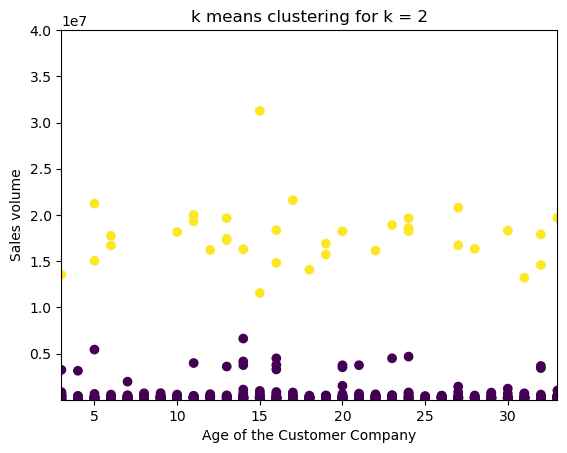

In [40]:
# plotting the clustering results
max(df['Sales' ])
plt.scatter(x = df['Age'], y = df['Sales'], c =df['Clusters'])
plt.xlabel("Age of the Customer Company")
plt.ylabel("Sales volume")
plt.title("k means clustering for k = 2")
plt.xlim(3,33)
plt.ylim(2000, 40000000)
plt.show()

- in todays lab we have performed k means clustering method
- intially we have assumed 4 cluster and we calculate silhouette_score which 58%
- then we draw a graph of that which indicates there are 2 cluster
- which is more accurate than 4 clusters
  